In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

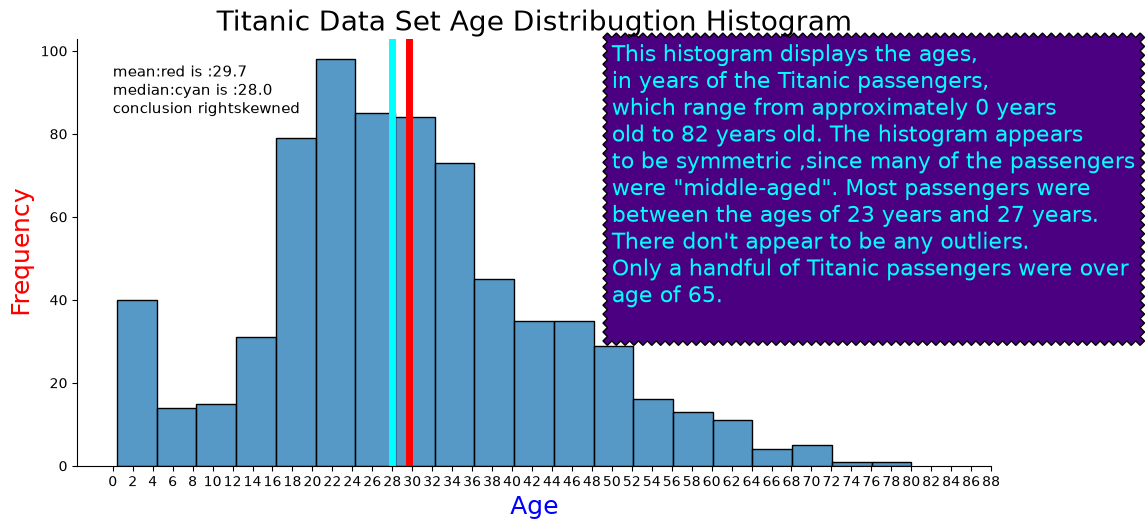

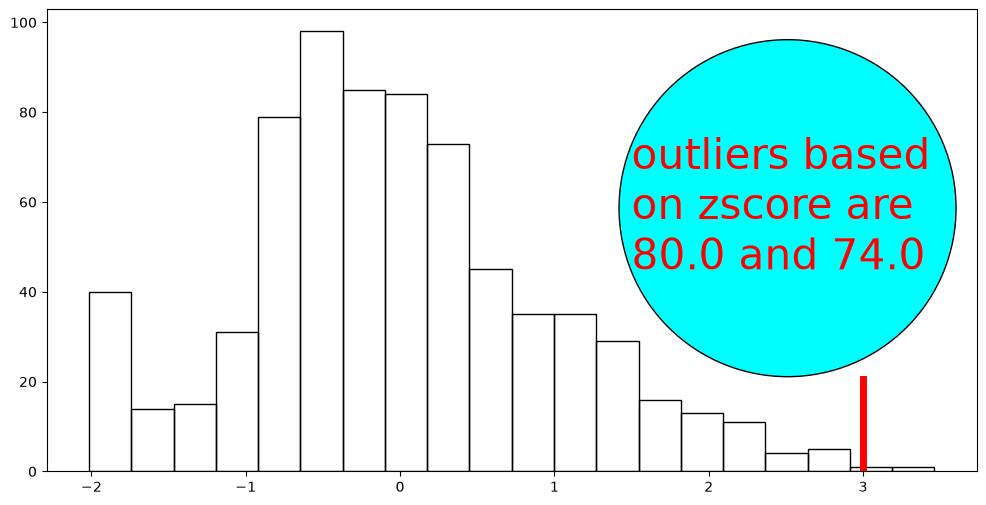

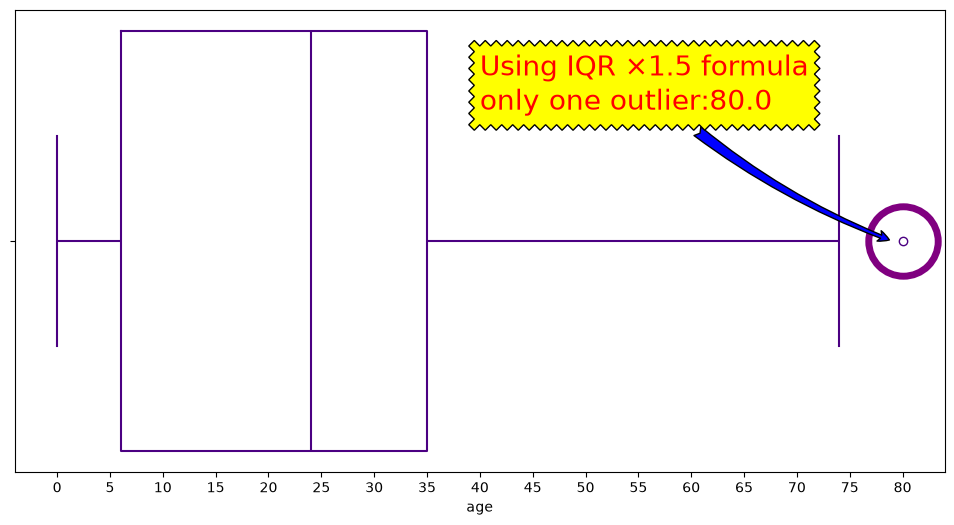

,df_age,Zscore_val,Zscore_abs,Outlier_usingIQR
630,80.0,3.462699,3.462699,outlier
851,74.0,3.049660,3.049660,normal


In [57]:
df=sns.load_dataset("titanic")
# sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="rainbow")
sns.displot(data=df,x=df['age'],
            aspect=2,height=5)
plt.title("Titanic Data Set Age Distribugtion Histogram",size=20,weight=400)
plt.xlabel("Age",size=18,color="blue")
plt.ylabel("Frequency",size=18,color="red")
plt.annotate("""This histogram displays the ages, 
in years of the Titanic passengers,
which range from approximately 0 years
old to 82 years old. The histogram appears 
to be symmetric ,since many of the passengers
were "middle-aged". Most passengers were 
between the ages of 23 years and 27 years.
There don't appear to be any outliers.
Only a handful of Titanic passengers were over 
age of 65.
""",xy=(50,33),size=16,color="cyan",
            bbox=dict(boxstyle="sawtooth,pad=0.4",facecolor="indigo"))
plt.xticks(np.arange(0,90,2))
plt.axvline(df['age'].mean(),color="red",lw=5)
plt.axvline(df['age'].median(),color="cyan",lw=5)
# plt.axvline(scipy.stats.mode(df['age']),color="green",lw=5)

plt.annotate("mean:red is :{}\nmedian:cyan is :{}\nconclusion rightskewned".\
    format(df['age'].mean().round(2),df['age'].median(),),xy=(0,85),size=11)
plt.show()
plt.figure(figsize=(12,6))
zscore_val=(df['age']-df['age'].mean())/df['age'].std()
plt.hist(zscore_val,fill=False,bins=20,color="red")
df_skew=pd.DataFrame({"df_age":df['age'],
                      "Zscore_val":zscore_val,
                      "Zscore_abs":np.abs(zscore_val)})

df['age']=df['age'].fillna(0)
Q1=np.percentile(df['age'],25)
Q3=np.percentile(df['age'],75)
IQR=Q3-Q1
Llim=Q1-IQR*1.5
Ulim=Q3+IQR*1.5

plt.annotate("outliers based \non zscore are \n{} and {}".format(df['age'][630],df['age'][851])
             ,xy=(1.5,45),color="red",size=30,bbox=dict(boxstyle="circle",facecolor="cyan"))
plt.axvline(x=3,ymin=0,ymax=0.2,lw=5,color="red",zorder=3,ls="-")


df_skew['Outlier_usingIQR']=np.where(~df_skew["df_age"].between(Llim,Ulim),"outlier","normal")

df_skew["df_age"]
df_skew.query("Zscore_abs>3")
plt.show()

plt.figure(figsize=(12,6))
plt.xticks(np.arange(0,100,5))
sns.boxplot(x=df['age'],fill=False,color="indigo",zorder=1)
plt.annotate("Using IQR $\\times$1.5 formula\nonly one outlier:{}".\
    format( df_skew["df_age"][630]),xytext=(40,-0.25),color="red",
            size=20,bbox=dict(boxstyle="sawtooth,pad=0.4",facecolor="yellow"),
            xy=(79,0.0),
            arrowprops=dict(arrowstyle="fancy",facecolor="blue",connectionstyle="arc3,rad=0.1"))
plt.plot(80,0,"o",ms=50,mfc="white",mec="purple",mew=5,zorder=0.5)
plt.show()

df_skew.query("Zscore_abs>3")